In [1]:
import os, sys, tempfile, subprocess
from coffea import processor
from coffea.nanoevents import NanoAODSchema, NanoEventsFactory
import matplotlib.pyplot as plt
import yaml

sidm_path = str(os.getcwd()).split('/sidm')[0]
if sidm_path not in sys.path:
    sys.path.insert(1, sidm_path)

from sidm.tools import utilities, scaleout, sidm_processor, llpnanoaodschema
from sidm.studies.cosmicVeto import functions
from sidm.studies.cosmicVeto import functions

utilities.set_plot_style()
%matplotlib inline

In [2]:
channels=  [ 
    "cr_Zmumu_noLJ",
    "cr_Zmumu_noLJ_prompt",
    "cr_Zmumu_noLJ_displaced",
           ]

samples_separate = ["TTJets",
               "DYJetsToLL",
               "QCD",
               "Diboson",
              # "data"
              ]
samples = ["bgs", "data"]
sum_hist= {}
for channel_name in channels:
    sum_hist[channel_name] = {}
for s in samples:
    if s == "data":
        list1= functions.get_data_files()
        list1 =  [x for x in list1 if "C" in x]
    elif s == "bgs":
        list1=[]
        for y in samples_separate:
            list2 = functions.get_bg_file_names(y)
            list1.extend(list2)
    else:
        list1 = functions.get_bg_file_names(s)
    for channel_name in channels:
        folder_name = f"OutputFiles/{channel_name}"
        sum_h= utilities.sum_hist(list1, folder_name)
        sum_hist[channel_name][s] = sum_h



In [3]:
sum_hist["cr_Zmumu_noLJ_displaced"].keys()

dict_keys(['bgs', 'data'])

[2.76381321e-03 2.75077817e-03 2.67636865e-03 2.87345098e-03
 3.89604590e-03 3.77023983e-03 8.51359643e-03 1.09925762e-02
 4.92808302e-03 8.30557113e-03 9.43510075e-06 1.91255878e-02
 0.00000000e+00 2.90375828e-05 0.00000000e+00 7.34107134e-05]
[0.00364347 0.00385283 0.00425891 0.00462903 0.00401152 0.0057328
 0.00422164 0.00622407 0.00365631 0.00626959 0.         0.
 0.         0.01785714 0.         0.        ]


/home/cms-jovyan/SIDM/sidm/tools/utilities.py:195: RuntimeWarning: invalid value encountered in divide
  num_counts = num_vals**2 / num_hist.variances()
/home/cms-jovyan/SIDM/sidm/tools/utilities.py:195: RuntimeWarning: invalid value encountered in divide
  num_counts = num_vals**2 / num_hist.variances()


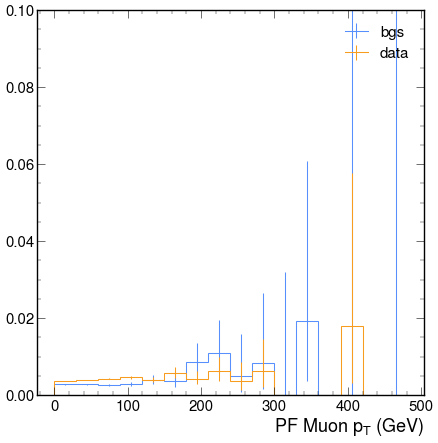

[0.00277161]
[0.00389511]


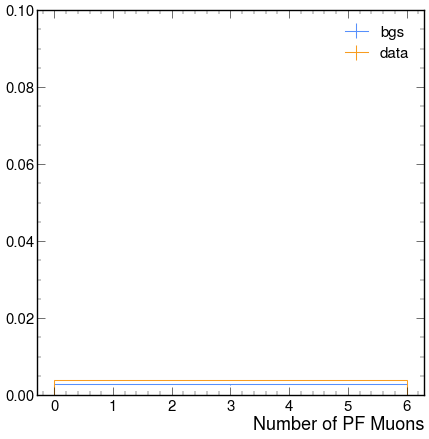

[6.02530398e-04 4.09425652e-03 5.29952131e-03 2.07420841e-03
 8.48729033e-04 3.84146923e-03 3.41757982e-02 1.56975747e-01
 2.34503866e-03 4.83067400e+00 2.11339445e-04 0.00000000e+00
 5.76645577e-05 1.28234997e-03 5.86114780e-05 0.00000000e+00]
[0.00191939 0.00410998 0.01002654 0.01070664 0.016      0.04444444
 0.03846154 0.         0.         0.         0.         0.06896552
 0.         0.         0.         0.        ]


/home/cms-jovyan/SIDM/sidm/tools/utilities.py:195: RuntimeWarning: invalid value encountered in divide
  num_counts = num_vals**2 / num_hist.variances()
/home/cms-jovyan/SIDM/sidm/tools/utilities.py:195: RuntimeWarning: invalid value encountered in divide
  num_counts = num_vals**2 / num_hist.variances()


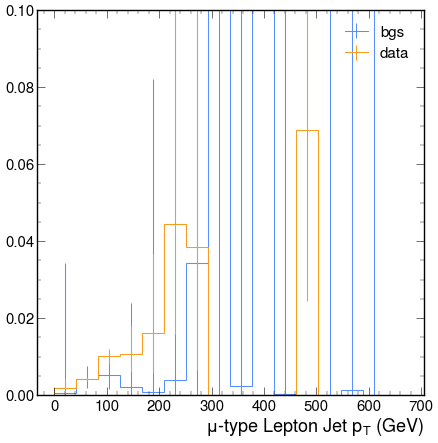

In [4]:
binning =2j
def plot_ratio_disp(histogram_name, binning=1j):
    for i, s in enumerate(samples):
        # ax =  axs[i]
        num_hist = sum_hist["cr_Zmumu_noLJ_displaced"][s][histogram_name]["cr_Zmumu_noLJ_displaced", ::binning]
        den_hist = sum_hist["cr_Zmumu_noLJ"][s][histogram_name]["cr_Zmumu_noLJ", ::binning]
        try:
            effi, err = utilities.get_eff_hist(num_hist, den_hist)
            utilities.plot(effi, yerr=err,label = s, skip_label=True)
            print(effi.values())
        except:
            print(f"using gaussian ratio for {s}")
            effi, err= utilities._gaussian_ratio(num_hist, den_hist)
            utilities.plot(effi,yerr=err, label = s, skip_label=True)
            
# plt.ylim(0, 10)
    plt.legend()

    # plt.yscale("log")
    plt.ylim(0, 0.1)
    plt.show()
hist_list = ["muon_pt", "muon_n", "mu_lj_pt"]
for histogram_name in hist_list:
    plot_ratio_disp (histogram_name, binning=6j)

[0.87712419 0.89971053 0.89756453 0.89782929 0.89945617 0.90864427
 0.89449982 0.89889464 0.90030733 0.88285272 0.85272371 0.90255857
 0.93091779 0.99818851 0.93814998 0.997055  ]
[0.84572155 0.87896858 0.87663036 0.87294445 0.8786258  0.87961117
 0.87124011 0.87551867 0.89213894 0.89028213 0.91666667 0.89830508
 0.89411765 0.89285714 0.94285714 1.        ]


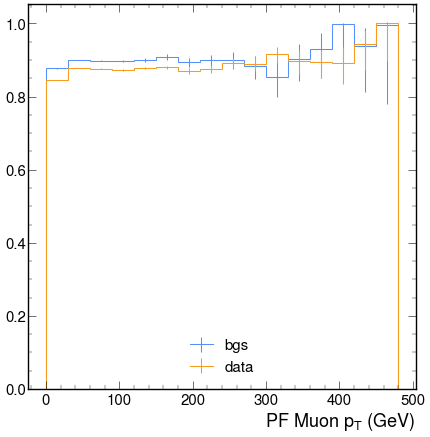

In [5]:
binning =2j
def plot_ratio_prompt(histogram_name, binning=1j):
    for i, s in enumerate(samples):
        # ax =  axs[i]
        num_hist = sum_hist["cr_Zmumu_noLJ_prompt"][s][histogram_name]["cr_Zmumu_noLJ_prompt", ::binning]
        den_hist = sum_hist["cr_Zmumu_noLJ"][s][histogram_name]["cr_Zmumu_noLJ", ::binning]
        try:
            effi, err = utilities.get_eff_hist(num_hist, den_hist)
            utilities.plot(effi, yerr=err,label = s, skip_label=True)
            print(effi.values())
        except:
            print(f"using gaussian ratio for {s}")
            effi, err= utilities._gaussian_ratio(num_hist, den_hist)
            utilities.plot(effi,yerr=err, label = s, skip_label=True)
            
# plt.ylim(0, 10)
    plt.legend()

    # plt.yscale("log")
    plt.show()
hist_list = ["muon_pt"]
for histogram_name in hist_list:
    plot_ratio_prompt (histogram_name, binning=6j)

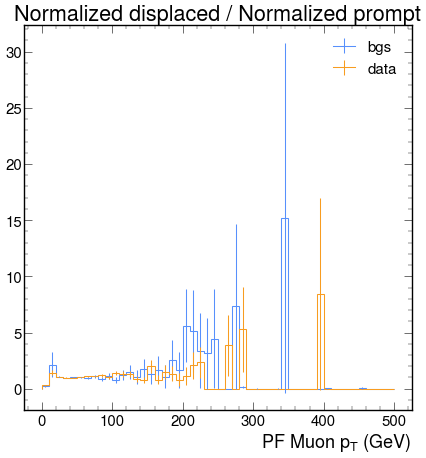

In [6]:
import numpy as np
import matplotlib.pyplot as plt


def normalize_hist(hist):
    """Normalize a histogram to unit area, accounting for bin widths."""
    values = hist.values()
    variances = hist.variances()
    bin_widths = np.diff(hist.axes[0].edges)
    norm = np.sum(values * bin_widths)
    if norm == 0:
        raise ValueError("Cannot normalize a histogram with zero integral.")
    hist.values()[...] = values / norm
    hist.variances()[...] = variances / norm**2
    return hist


for p in samples:
    prompt_hist = sum_hist["cr_Zmumu_noLJ_prompt"][p][histogram_name][
        "cr_Zmumu_noLJ_prompt", ::binning
    ].copy()

    disp_hist = sum_hist["cr_Zmumu_noLJ_displaced"][p][histogram_name][
        "cr_Zmumu_noLJ_displaced", ::binning
    ].copy()

    prompt_hist = normalize_hist(prompt_hist)
    disp_hist = normalize_hist(disp_hist)

    ratio, err = utilities._gaussian_ratio(disp_hist, prompt_hist)

    utilities.plot(ratio, yerr=err, label=p, skip_label=True)

plt.legend()
plt.title("Normalized displaced / Normalized prompt")
plt.show()

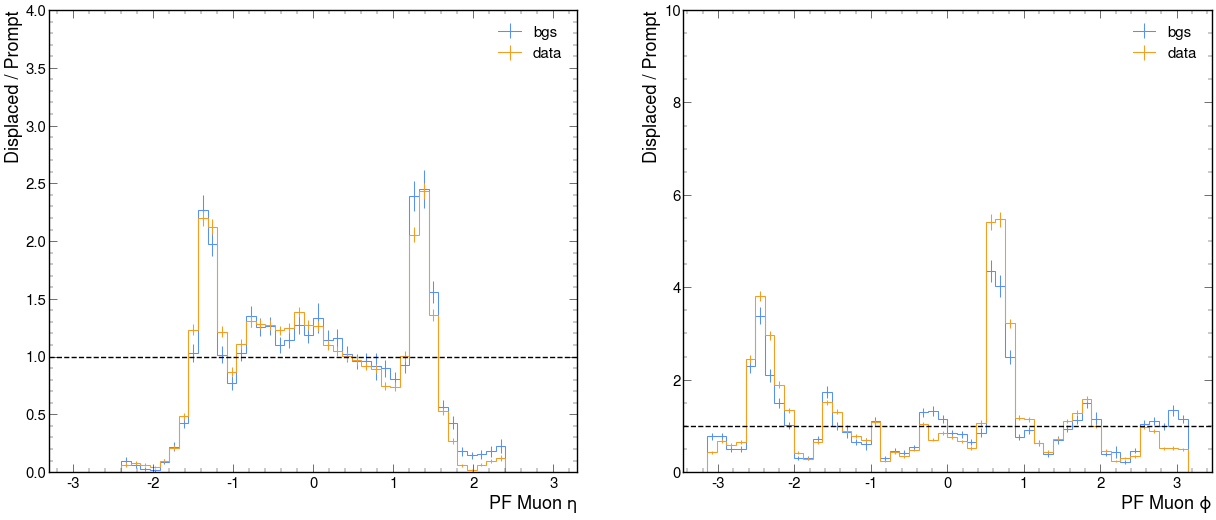

In [7]:
fig, axs = plt.subplots(1, 2, figsize = (30, 12))
for p in samples:
    histogram_prompt  = sum_hist["cr_Zmumu_noLJ_prompt"][p]["muon_eta_phi"][
    "cr_Zmumu_noLJ_prompt", :, :]
    histogram_disp  = sum_hist["cr_Zmumu_noLJ_displaced"][p]["muon_eta_phi"][
    "cr_Zmumu_noLJ_displaced", :, :]

    prompt_eta = functions.plot_1d (histogram_prompt, "muons_eta" )
    prompt_phi = functions.plot_1d (histogram_prompt, "muons_phi" )
    disp_eta = functions.plot_1d (histogram_disp, "muons_eta" )
    disp_phi = functions.plot_1d (histogram_disp, "muons_phi" )

    
    prompt_hist_eta = normalize_hist(prompt_eta)
    disp_hist_eta = normalize_hist(disp_eta)

    prompt_hist_phi = normalize_hist(prompt_phi)
    disp_hist_phi = normalize_hist(disp_phi)

    ratio, err = utilities._gaussian_ratio(disp_hist_eta, prompt_hist_eta)

    utilities.plot(ratio, yerr=err, label=p, skip_label=True, ax =axs[0])

    ratio, err = utilities._gaussian_ratio(disp_hist_phi, prompt_hist_phi)

    utilities.plot(ratio, yerr=err, label=p, skip_label=True, ax =axs[1])


plt.legend()

axs[0].set_ylabel("Displaced / Prompt")

axs[1].set_ylabel("Displaced / Prompt")

axs [0].set_ylim(0, 4)
axs [1].set_ylim(0, 10)

axs[0].legend()
axs[0].axhline(y=1, linestyle="--", linewidth=2, color="k")
axs[1].axhline(y=1, linestyle="--", linewidth=2,  color="k")
axs[1].legend()
plt.show()

/home/cms-jovyan/SIDM/sidm/tools/utilities.py:190: RuntimeWarning: invalid value encountered in divide
  eff_values = num_vals/denom_vals
/home/cms-jovyan/SIDM/sidm/tools/utilities.py:195: RuntimeWarning: invalid value encountered in divide
  num_counts = num_vals**2 / num_hist.variances()
/home/cms-jovyan/SIDM/sidm/tools/utilities.py:196: RuntimeWarning: invalid value encountered in divide
  denom_counts = denom_vals**2 / denom_hist.variances()
/home/cms-jovyan/SIDM/sidm/tools/utilities.py:190: RuntimeWarning: invalid value encountered in divide
  eff_values = num_vals/denom_vals
/home/cms-jovyan/SIDM/sidm/tools/utilities.py:195: RuntimeWarning: invalid value encountered in divide
  num_counts = num_vals**2 / num_hist.variances()
/home/cms-jovyan/SIDM/sidm/tools/utilities.py:196: RuntimeWarning: invalid value encountered in divide
  denom_counts = denom_vals**2 / denom_hist.variances()


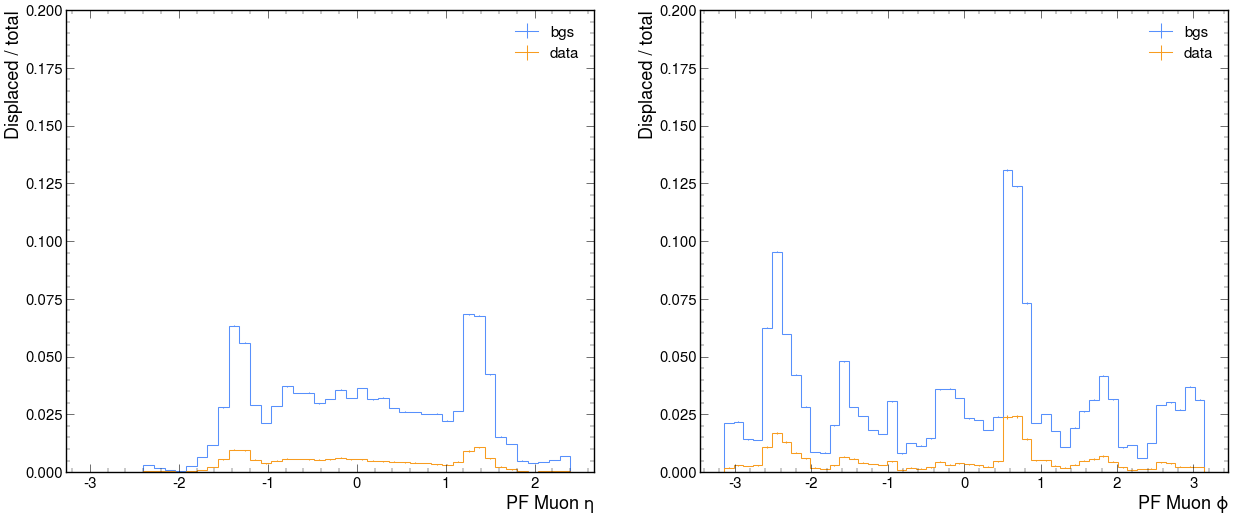

In [11]:
fig, axs = plt.subplots(1, 2, figsize = (30, 12))
for p in samples:
    histogram  = sum_hist["cr_Zmumu_noLJ"][p]["muon_eta_phi"][
    "cr_Zmumu_noLJ", :, :]
    histogram_disp  = sum_hist["cr_Zmumu_noLJ_displaced"][p]["muon_eta_phi"][
    "cr_Zmumu_noLJ_displaced", :, :]

    eta = functions.plot_1d (histogram_prompt, "muons_eta" )
    phi = functions.plot_1d (histogram_prompt, "muons_phi" )
    disp_eta = functions.plot_1d (histogram_disp, "muons_eta" )
    disp_phi = functions.plot_1d (histogram_disp, "muons_phi" )

    
    # hist_eta = normalize_hist(prompt_eta)
    # disp_hist_eta = normalize_hist(disp_eta)

    # hist_phi = normalize_hist(prompt_phi)
    # disp_hist_phi = normalize_hist(disp_phi)

    ratio, err = utilities.get_eff_hist(disp_eta, eta)

    utilities.plot(ratio, yerr=err, label=p, skip_label=True, ax =axs[0])

    ratio, err = utilities.get_eff_hist(disp_phi, phi)

    utilities.plot(ratio, yerr=err, label=p, skip_label=True, ax =axs[1])


plt.legend()

axs[0].set_ylabel("Displaced / total")

axs[1].set_ylabel("Displaced / total")

axs [0].set_ylim(0, 0.2)
axs [1].set_ylim(0, 0.2)

axs[0].legend()
axs[0].axhline(y=1, linestyle="--", linewidth=2, color="k")
axs[1].axhline(y=1, linestyle="--", linewidth=2,  color="k")
axs[1].legend()
plt.show()